# 04: Store statistics and autocorrelation
Goal: see how store size relates to variability, and which lags carry signal for lag features.
Data is loaded through `forecast.data` (validated loader).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from forecast.data import load_visits

FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

visits = load_visits()
print(visits.shape, visits["air_store_id"].nunique())

(252108, 3) 829


In [2]:
per_store = visits.groupby("air_store_id")["visitors"].agg(["mean", "std", "count"])
per_store = per_store[per_store["count"] >= 30].copy()
per_store["cv"] = per_store["std"] / per_store["mean"]
print(len(per_store))
print(per_store[["mean", "std", "cv"]].corr().round(2))
print(per_store[["mean", "std", "cv"]].corr(method="spearman").round(2))

828
      mean   std    cv
mean  1.00  0.71 -0.34
std   0.71  1.00  0.30
cv   -0.34  0.30  1.00
      mean   std    cv
mean  1.00  0.82 -0.42
std   0.82  1.00  0.11
cv   -0.42  0.11  1.00


max gap in days: 1.0
7     0.77
14    0.69
21    0.67
28    0.67
1     0.49
dtype: float64


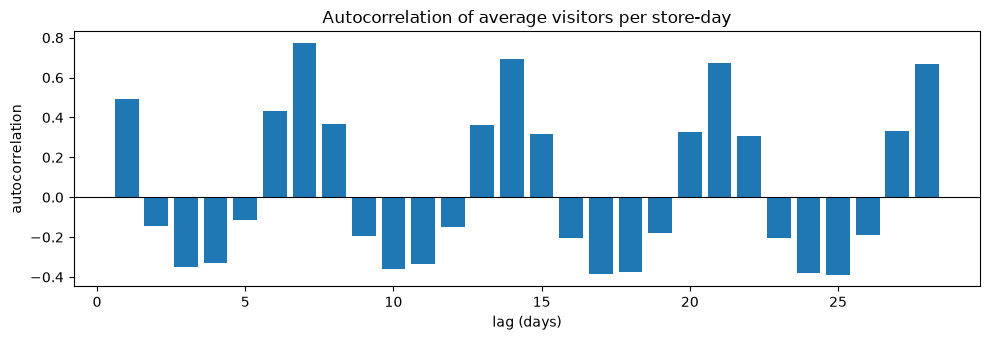

In [3]:
daily_avg = visits.groupby("visit_date")["visitors"].mean()
print("max gap in days:", daily_avg.index.to_series().diff().dt.days.max())

acf = pd.Series({k: daily_avg.autocorr(k) for k in range(1, 29)})
print(acf.sort_values(ascending=False).head(5).round(2))

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(acf.index, acf.values)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("lag (days)")
ax.set_ylabel("autocorrelation")
ax.set_title("Autocorrelation of average visitors per store-day")
fig.tight_layout()
fig.savefig(FIG / "autocorr_daily.png", dpi=120)
plt.show()

In [4]:
top = visits["air_store_id"].value_counts().index[0]
s = visits[visits["air_store_id"] == top].set_index("visit_date")["visitors"].asfreq("D")
print("days:", len(s), "| missing:", s.isna().sum())
print("lag-1:", round(s.autocorr(1), 2), "| lag-7:", round(s.autocorr(7), 2))

days: 477 | missing: 0
lag-1: 0.3 | lag-7: 0.59


## Key findings
1. Store size and variability: across the 828 of 829 stores with at least 30 rows, the mean and the std of daily visitors are strongly positively correlated (Pearson 0.71, Spearman 0.82). Bigger stores have bigger absolute swings, so MAE is dominated by large stores and a relative metric such as RMSLE is a better fit.
2. Relative variability: the coefficient of variation (cv) correlates negatively with the store mean (Pearson -0.34, Spearman -0.42). Its correlation with the std is 0.30 (Pearson) but only 0.11 (Spearman), partly by construction since cv = std / mean. Larger stores are relatively steadier, while small stores are noisier compared with their size and will be harder to forecast.
3. Autocorrelation: for the daily average visitors per store-day (no missing dates), the autocorrelation is highest at lag 7 (0.77), followed by lag 14 (0.69) and lags 21 and 28 (both 0.67); lag 1 is 0.49. The bars form a 7-day wave, positive around multiples of 7 and negative about half a week in between, so there is a weekly pattern that decays only slowly.
4. Single store: for the store with the most rows (477 days, no gaps), lag 7 is 0.59 and lag 1 is 0.30, lower than the aggregate because one store is noisier than the average of all stores.